# Notebook 5 — Relatório Final

**TCC — Desenvolvimento de modelo preditivo interpretável de machine learning para
identificação de alunos em risco de evasão no ensino superior**
Curso de Sistemas de Informação — UEMG

---

## O que este notebook é

Consolidação dos resultados das quatro fases executadas. Não produz análise nova: **reúne, verifica e
apresenta** o que os Notebooks 1 a 4 estabeleceram, em formato utilizável na redação da monografia e
na defesa.

Além da consolidação, a seção 5 traz o único elemento inédito: uma **demonstração de uso ponta a
ponta**, que recebe os dados brutos de um aluno e devolve probabilidade de evasão, explicação
individual e encaminhamento sugerido. É a prova de que os artefatos salvos compõem uma ferramenta
funcional, e não apenas um conjunto de números.

| Seção | Conteúdo |
|---|---|
| 1 | Resumo executivo |
| 2 | Ficha técnica do modelo final |
| 3 | Os 10 fatores de risco identificados |
| 4 | Painel consolidado de resultados |
| 5 | Demonstração de uso: do dado bruto ao encaminhamento |
| 6 | Limitações do estudo |
| 7 | Trabalhos futuros, priorizados |
| 8 | Conclusão |

## 0. Carga dos artefatos

In [1]:
import os
import sys
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    matthews_corrcoef, balanced_accuracy_score,
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

DIR_DADOS, DIR_FIGURAS, DIR_MODELOS = "dados", "figuras", "modelos"

if "src" not in sys.path:
    sys.path.insert(0, "src")
from data_loader import rotulo, tipologia   # noqa: E402

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
})

def salvar(nome):
    caminho = os.path.join(DIR_FIGURAS, nome)
    plt.savefig(caminho)
    print(f"[figura salva] {caminho}")

# --- Artefatos de todas as fases --------------------------------------------
df_limpo = pd.read_csv(os.path.join(DIR_DADOS, "dataset_limpo.csv"))
X_teste = pd.read_csv(os.path.join(DIR_DADOS, "X_test.csv"))
y_teste = pd.read_csv(os.path.join(DIR_DADOS, "y_test.csv"))["target"]
metricas = pd.read_csv(os.path.join(DIR_DADOS, "metricas_modelos.csv"), index_col=0)
limiares = pd.read_csv(os.path.join(DIR_DADOS, "analise_limiar.csv"))
shap_imp = pd.read_csv(os.path.join(DIR_DADOS, "shap_importancia_global.csv"))
shap_dir = pd.read_csv(os.path.join(DIR_DADOS, "shap_direcao_efeito.csv"))
shap_grp = pd.read_csv(os.path.join(DIR_DADOS, "shap_grupos_conceituais.csv"))

with open(os.path.join(DIR_DADOS, "metadados.json"), encoding="utf-8") as fh:
    META = json.load(fh)
with open(os.path.join(DIR_MODELOS, "info_melhor_modelo.json"), encoding="utf-8") as fh:
    INFO = json.load(fh)

preprocessador = joblib.load(os.path.join(DIR_MODELOS, "preprocessador.joblib"))
pipeline = joblib.load(os.path.join(DIR_MODELOS, "melhor_modelo.joblib"))
modelo = pipeline.named_steps["modelo"]

CLASSES = {int(k): v for k, v in META["classes"].items()}
MELHOR = INFO["melhor_modelo"]

print(f"Artefatos carregados. Modelo final: {MELHOR}")
print(f"Fases consolidadas: 2 (exploração), 3 (preparação), 4 (modelagem), 5 (interpretabilidade)")

Artefatos carregados. Modelo final: XGBoost
Fases consolidadas: 2 (exploração), 3 (preparação), 4 (modelagem), 5 (interpretabilidade)


## 1. Resumo executivo

### O problema

A evasão no ensino superior é um fenômeno de alto custo — para o aluno, que interrompe sua formação;
para a instituição, que perde receita e vaga ocupada; e para o sistema educacional, que desperdiça
investimento público. Na base analisada, **32,1% dos 4.424 estudantes evadiram**.

A dificuldade prática não é reconhecer a evasão depois que ela ocorre, e sim **identificar, com
antecedência suficiente para intervir, quais alunos estão em risco** — e, sobretudo, **por quê**, já
que a intervenção adequada depende da causa.

### A abordagem

Pipeline completo em CRISP-DM, com duas prioridades declaradas desde o início:

1. **Controle rigoroso de vazamento de informação.** Separação treino/teste antes de qualquer
   transformação; `StandardScaler`, `OneHotEncoder` e SMOTE ajustados exclusivamente no treino; SMOTE
   reaplicado por dobra na validação cruzada. Cada uma dessas condições tem verificação automática que
   **aborta a execução** se violada.
2. **Interpretabilidade como requisito, não como acessório.** O produto final não é uma lista de
   nomes, mas uma lista de nomes **com o motivo de cada um**, para que o encaminhamento seja possível.

### O resultado

Três modelos comparados — Regressão Logística, Random Forest e XGBoost. O **XGBoost** foi selecionado
por F1 da classe `Dropout`, com PR-AUC como desempate.

| Métrica | Partição avaliada (semente 42) | Partição típica (10 sementes) |
|---|---|---|
| **F1-score (Dropout)** | **0,9059** | **≈ 0,88** (0,866 – 0,891) |
| **Recall** | **0,8979** — 90 de cada 100 que evadem | **0,8437** — **84** de cada 100 (82 – 86) |
| **Precisão** | **0,9140** — 91 de cada 100 sinalizados | **0,9191** — 92 de cada 100, **sem viés** |
| ROC-AUC | 0,9747 | — |

**Ressalva de partição, no mesmo fôlego que os números.** Estes valores são da partição da semente 42,
que a Verificação 2 mostrou ser **favorável**. Em partições típicas o F1 é **≈ 0,88** e o modelo
identifica **84 de cada 100** evadidos, não 90 (faixa 82–86). A precisão **não** apresenta esse viés —
mantém-se em ≈ 92 de cada 100 sinalizados.

### Os quatro achados que sustentam a defesa

1. **O sinal está nos dados, não no algoritmo.** O ganho do XGBoost sobre a linha de base linear é de
   apenas **+1,4% em F1**, e Random Forest e XGBoost empatam exatamente. Como a complexidade rende
   pouco, **a interpretabilidade passa a ser critério legítimo de decisão, não concessão** — o que
   sustenta diretamente o objetivo do trabalho.

2. **Desempenho acadêmico inicial e situação financeira concentram o risco.** Juntos respondem por
   **74,8%** do impacto nas predições. O achado se reproduz em três métodos independentes: correlação
   linear, redução de impureza e valores de Shapley.

3. **Efeito marginal e efeito condicional divergem em três variáveis.** A taxa de desemprego tem
   correlação marginal de −0,004 com a evasão — qualquer filtro univariado a descartaria — e é a **9ª
   variável mais importante** do modelo. É a justificativa empírica para não ter feito seleção de
   variáveis.

4. **Existe um teto que não depende do algoritmo.** O falso negativo analisado evadiu tendo perfil
   protetor em todos os indicadores disponíveis. As causas de parte das evasões **não estão nas 36
   variáveis**, e nenhum ajuste de modelagem recuperaria esses 29 alunos — 44 em uma partição típica,
   pela Verificação 2.

### A recomendação central

> O sistema deve ser entregue à coordenação como **instrumento de priorização acompanhado de
> explicação individual**, nunca como veredito. Cada aluno sinalizado vem com seus três principais
> fatores, e o encaminhamento segue o fator dominante: inadimplência → assistência estudantil;
> reprovações → apoio pedagógico; poucas avaliações → contato direto.
>
> E, por causa do achado 4: **um aluno não sinalizado não é um aluno seguro.**

## 2. Ficha técnica do modelo final

In [2]:
# --- Reconstrói as predições para conferir os números reportados ------------
y_pred = pipeline.predict(X_teste)
y_prob = pipeline.predict_proba(X_teste)[:, 1]
vn, fp, fn, vp = confusion_matrix(y_teste, y_pred).ravel()

ficha = {
    "Modelo": MELHOR,
    "Formulação": f"binária — {CLASSES[1]} × {CLASSES[0]}",
    "Classe positiva": CLASSES[1],
    "Features de entrada": META["n_features"],
    "Registros de treino (após SMOTE)": META["n_treino_apos_smote"],
    "Registros de teste": META["n_teste"],
    "Taxa de evasão no teste": f"{META['prop_evasao_teste']:.1%}",
    "Semente aleatória": META["seed"],
}
print("CONFIGURAÇÃO")
for k, v in ficha.items():
    print(f"   {k:<34} {v}")

print()
print("HIPERPARÂMETROS")
for k in ("n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree"):
    print(f"   {k:<34} {INFO['hiperparametros'][k]}")

print()
print("DESEMPENHO NO CONJUNTO DE TESTE (726 alunos reais, sem dados sintéticos)")
desempenho = pd.DataFrame({
    "valor": {
        "Acurácia": accuracy_score(y_teste, y_pred),
        "Acurácia balanceada": balanced_accuracy_score(y_teste, y_pred),
        "Precisão (Dropout)": precision_score(y_teste, y_pred),
        "Recall (Dropout)": recall_score(y_teste, y_pred),
        "F1-score (Dropout)": f1_score(y_teste, y_pred),
        "ROC-AUC": roc_auc_score(y_teste, y_prob),
        "PR-AUC": average_precision_score(y_teste, y_prob),
        "MCC": matthews_corrcoef(y_teste, y_pred),
    }
}).round(4)
display(desempenho)

# confere contra o que o Notebook 3 registrou
divergencias = {
    k: (v, INFO["metricas_teste"].get(k))
    for k, v in [("F1", f1_score(y_teste, y_pred)), ("recall", recall_score(y_teste, y_pred))]
    if k in INFO["metricas_teste"] and abs(v - INFO["metricas_teste"][k]) > 1e-9
}
print(f"\nConferência contra o Notebook 3: "
      f"{'DIVERGÊNCIA -> ' + str(divergencias) if divergencias else 'valores idênticos'}")

CONFIGURAÇÃO
   Modelo                             XGBoost
   Formulação                         binária — Dropout × Graduate
   Classe positiva                    Dropout
   Features de entrada                105
   Registros de treino (após SMOTE)   3534
   Registros de teste                 726
   Taxa de evasão no teste            39.1%
   Semente aleatória                  42

HIPERPARÂMETROS
   n_estimators                       200
   max_depth                          3
   learning_rate                      0.1
   subsample                          1.0
   colsample_bytree                   0.8

DESEMPENHO NO CONJUNTO DE TESTE (726 alunos reais, sem dados sintéticos)


,valor
Acurácia,0.9270
Acurácia balanceada,0.9218
Precisão (Dropout),0.9140
Recall (Dropout),0.8979
F1-score (Dropout),0.9059
ROC-AUC,0.9747
PR-AUC,0.9741
MCC,0.8463



Conferência contra o Notebook 3: valores idênticos


In [3]:
# --- Tradução da matriz de confusão ----------------------------------------
print("MATRIZ DE CONFUSÃO — leitura operacional")
print()
print(f"   {vp:>3}  evadidos corretamente sinalizados")
print(f"   {fn:>3}  evadidos NÃO detectados          <- o erro caro")
print(f"   {fp:>3}  concluintes sinalizados por engano")
print(f"   {vn:>3}  concluintes corretamente liberados")
print()
print(f"   De cada 100 alunos que evadem, o modelo identifica {vp / (vp + fn) * 100:.0f}.")
print(f"   De cada 100 alunos sinalizados, {vp / (vp + fp) * 100:.0f} realmente evadiriam.")
print(f"   Alunos convocados: {vp + fp} de {len(y_teste)} ({(vp + fp) / len(y_teste) * 100:.1f}% da turma).")
print()
print("CALIBRAÇÃO DO LIMIAR — alternativas institucionais")
print()
print(f"   {'limiar':>7}  {'sinalizados':>12}  {'não detectados':>15}  {'falsos alarmes':>15}")
for t in (0.20, 0.30, 0.40, 0.50, 0.60, 0.70):
    linha = limiares.iloc[(limiares["limiar"] - t).abs().idxmin()]
    detectados = round(linha["recall"] * y_teste.sum())
    nao_det = int(y_teste.sum() - detectados)
    falsos = int(linha["sinalizados"] - detectados)
    marca = "  <- adotado" if abs(t - 0.5) < 1e-9 else ""
    print(f"   {t:>7.2f}  {int(linha['sinalizados']):>12}  {nao_det:>15}  {falsos:>15}{marca}")

MATRIZ DE CONFUSÃO — leitura operacional

   255  evadidos corretamente sinalizados
    29  evadidos NÃO detectados          <- o erro caro
    24  concluintes sinalizados por engano
   418  concluintes corretamente liberados

   De cada 100 alunos que evadem, o modelo identifica 90.
   De cada 100 alunos sinalizados, 91 realmente evadiriam.
   Alunos convocados: 279 de 726 (38.4% da turma).

CALIBRAÇÃO DO LIMIAR — alternativas institucionais

    limiar   sinalizados   não detectados   falsos alarmes
      0.20           366                8               90
      0.30           330               12               58
      0.40           307               17               40
      0.50           279               29               24  <- adotado
      0.60           265               32               13
      0.70           250               42                8


## 3. Os 10 fatores de risco identificados

Ranking pelo valor SHAP, com a direção do efeito medida pela correlação de Spearman entre o valor da
variável e sua contribuição. **Este é o resultado substantivo do trabalho** — o que ele afirma sobre a
evasão, e não apenas sobre o modelo.

In [4]:
# --- Consolida importância + direção ---------------------------------------
top10 = shap_imp.head(10).merge(
    shap_dir[["variavel", "rho_valor_x_shap", "efeito de valor alto"]],
    on="variavel", how="left",
)
top10.columns = ["#", "variável", "impacto (SHAP)", "% do total", "% acum.", "rho", "direção"]
display(top10.round(4))

print("Concentração do impacto:")
for k in (3, 5, 10):
    print(f"   top {k:>2}: {shap_imp['% acumulado'].iloc[k - 1]:5.1f}%")
print()
print("Por grupo conceitual:")
for _, r in shap_grp.iterrows():
    print(f"   {r['grupo']:<26} {r['% do total']:>5.1f}%   ({int(r['n_features'])} features)")

academico_financeiro = shap_grp[
    shap_grp["grupo"].isin(["Desempenho acadêmico", "Situação financeira"])]["% do total"].sum()
print()
print(f"Desempenho acadêmico + situação financeira = {academico_financeiro:.1f}% do impacto total")

,#,variável,impacto (SHAP),% do total,% acum.,rho,direção
0,1,Disciplinas aprovadas (2º sem.),1.5425,23.38,23.38,-0.9667,REDUZ o risco
1,2,Disciplinas aprovadas (1º sem.),0.8258,12.52,35.90,-0.9564,REDUZ o risco
2,3,Mensalidades em dia,0.4232,6.42,42.32,-0.6043,REDUZ o risco
3,4,Disciplinas matriculadas (1º sem.),0.3918,5.94,48.26,0.7180,AUMENTA o risco
4,5,Média das notas (2º sem.),0.2509,3.80,52.06,-0.8944,REDUZ o risco
5,6,Bolsista,0.2419,3.67,55.73,-0.7394,REDUZ o risco
6,7,Nota de admissão,0.2401,3.64,59.37,0.2541,não monotônico
7,8,Idade no ingresso,0.2032,3.08,62.45,0.7864,AUMENTA o risco
8,9,Taxa de desemprego,0.1799,2.73,65.18,0.9429,AUMENTA o risco
9,10,Inadimplente,0.1758,2.67,67.85,0.5540,AUMENTA o risco


Concentração do impacto:
   top  3:  42.3%
   top  5:  52.1%
   top 10:  67.8%

Por grupo conceitual:
   Desempenho acadêmico        59.9%   (12 features)
   Situação financeira         14.9%   (3 features)
   Trajetória de ingresso       9.5%   (36 features)
   Perfil demográfico           5.7%   (11 features)
   Contexto macroeconômico      5.1%   (3 features)
   Origem familiar              4.9%   (40 features)

Desempenho acadêmico + situação financeira = 74.8% do impacto total


### Interpretação de cada fator

| # | Fator | Direção | Leitura substantiva |
|---:|---|---|---|
| 1 | **Disciplinas aprovadas (2º sem.)** | menos aprovações → mais risco | O fator dominante, com 23,4% do impacto. A mediana entre evadidos é **zero** — o aluno para de aprovar antes de formalizar a saída. **Gatilho: até 3 aprovações.** |
| 2 | **Disciplinas aprovadas (1º sem.)** | menos aprovações → mais risco | Mesmo mecanismo, um semestre antes. **Gatilho: até 4 aprovações.** Permite alerta seis meses mais cedo. |
| 3 | **Mensalidades em dia** | atraso → mais risco | Entre alunos em atraso, a evasão é de **86,6%**, contra 24,7% dos adimplentes. O efeito é assimétrico: o atraso contribui com +1,86, a adimplência com apenas −0,19. |
| 4 | **Disciplinas matriculadas (1º sem.)** | **mais matrículas → mais risco** | Contraintuitivo, e explicável: *dado* o número de aprovações, matricular-se em muitas sinaliza **sobrecarga e reprovação acumulada**. Matricular 8 e aprovar 1 é o padrão de risco. |
| 5 | **Média das notas (2º sem.)** | nota baixa → mais risco | Cai da 1ª para a 5ª posição em relação aos Notebooks 1 e 2: condicionada às aprovações, a média agrega pouco. **Gatilho: até 11** na escala 0–20. |
| 6 | **Bolsista** | bolsa → menos risco | Bolsistas evadem a **12,2%**, contra 38,7% — menos de um terço do risco. Fator protetor mais forte do conjunto. |
| 7 | **Nota de admissão** | não monotônico | Único fator do top 10 sem direção consistente (ρ = +0,25). O efeito muda de sinal ao longo da faixa; interpretação exige o gráfico de dependência. |
| 8 | **Idade no ingresso** | idade maior → mais risco | Mediana de 23 anos entre evadidos, 19 entre concluintes. **Gatilho: 23 anos ou mais.** É marcador de responsabilidades concorrentes, não causa. |
| 9 | **Taxa de desemprego** | desemprego alto → mais risco | Correlação marginal de **−0,004** e ainda assim 9ª mais importante. Só aparece condicionada ao perfil individual — confirma a literatura por um caminho que a análise descritiva não veria. |
| 10 | **Inadimplente** | dívida → mais risco | Reforça o bloco financeiro. Taxa de evasão de 62,0% entre inadimplentes, contra 28,3%. |

### O agrupamento que importa para a política institucional

**Desempenho acadêmico (59,9%) + situação financeira (14,9%) = 74,8% do impacto.**

A distinção entre os dois blocos é operacionalmente decisiva:

- o bloco **financeiro** é diretamente acionável por política institucional — bolsa, renegociação,
  auxílio permanência;
- o bloco **acadêmico** exige intervenção pedagógica — monitoria, tutoria, revisão de carga.

Em contraste, **origem familiar responde por apenas 4,9% do impacto com 40 das 105 features** — a
maior contagem de variáveis e o menor efeito. O capital cultural provavelmente atua **mediado** pelo
desempenho acadêmico, que já está no modelo.

## 4. Painel consolidado

[figura salva] figuras\21_painel_consolidado.png


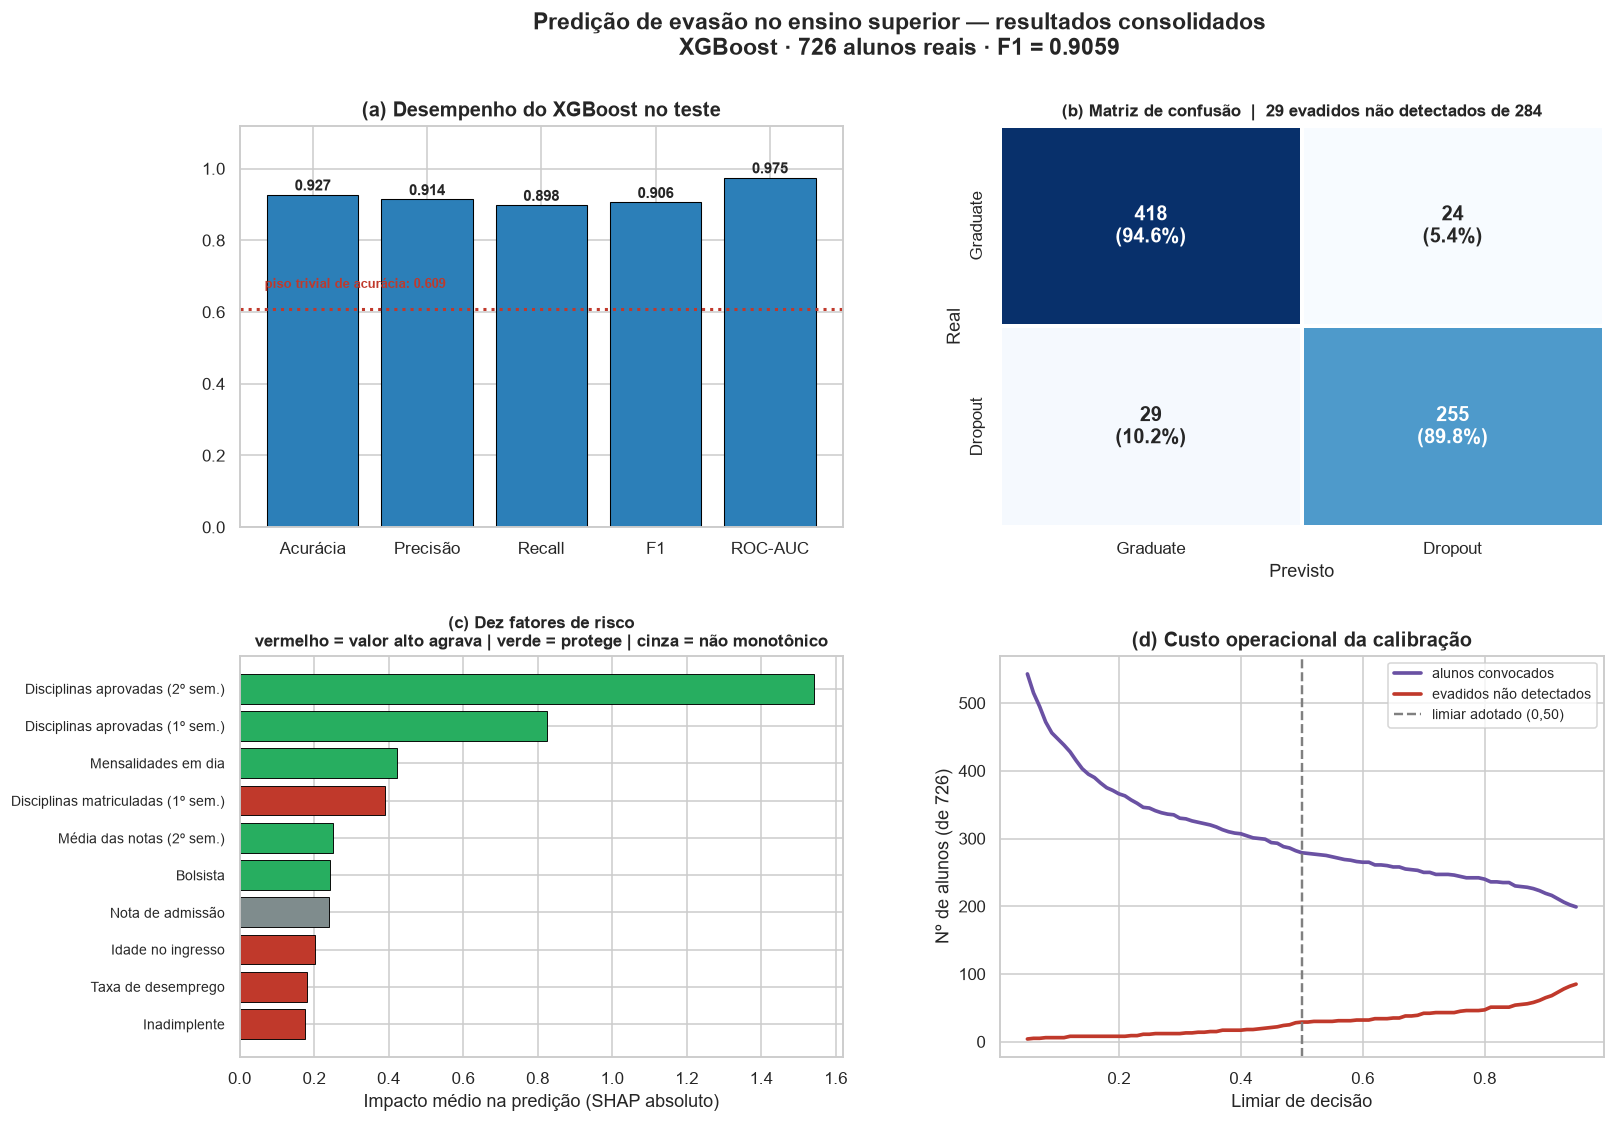

In [5]:
fig = plt.figure(figsize=(16, 11))
grade = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.26)

# (a) métricas do modelo final contra o piso trivial
ax = fig.add_subplot(grade[0, 0])
nomes = ["Acurácia", "Precisão", "Recall", "F1", "ROC-AUC"]
valores = [accuracy_score(y_teste, y_pred), precision_score(y_teste, y_pred),
           recall_score(y_teste, y_pred), f1_score(y_teste, y_pred),
           roc_auc_score(y_teste, y_prob)]
barras = ax.bar(nomes, valores, color="#2c7fb8", edgecolor="black", linewidth=0.7)
for b, v in zip(barras, valores):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.012, f"{v:.3f}",
            ha="center", fontweight="bold", fontsize=9.5)
piso = 1 - y_teste.mean()
ax.axhline(piso, color="#c0392b", linestyle=":", linewidth=2)
ax.text(-0.42, piso + 0.05, f"piso trivial de acurácia: {piso:.3f}",
        color="#c0392b", fontsize=8.5, fontweight="bold", va="bottom")
ax.set_ylim(0, 1.12)
ax.set_title(f"(a) Desempenho do {MELHOR} no teste")

# (b) matriz de confusão
ax = fig.add_subplot(grade[0, 1])
mc = confusion_matrix(y_teste, y_pred)
anot = np.array([[f"{mc[i, j]}\n({mc[i, j] / mc[i].sum() * 100:.1f}%)"
                  for j in range(2)] for i in range(2)], dtype=object)
sns.heatmap(mc, annot=anot, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[CLASSES[0], CLASSES[1]], yticklabels=[CLASSES[0], CLASSES[1]],
            annot_kws={"size": 13, "weight": "bold"}, linewidths=1.4, linecolor="white")
ax.set_xlabel("Previsto")
ax.set_ylabel("Real")
ax.set_title("(b) Matriz de confusão  |  " + str(fn) +
             " evadidos não detectados de " + str(int(y_teste.sum())), fontsize=11)

# (c) top 10 fatores, coloridos pela direção
ax = fig.add_subplot(grade[1, 0])
t10 = shap_imp.head(10).merge(shap_dir[["variavel", "rho_valor_x_shap"]], on="variavel", how="left")
t10 = t10.iloc[::-1]
cores = ["#c0392b" if r > 0.30 else "#27ae60" if r < -0.30 else "#7f8c8d"
         for r in t10["rho_valor_x_shap"]]
ax.barh(t10["variavel"], t10["shap_medio_abs"], color=cores, edgecolor="black", linewidth=0.6)
ax.set_xlabel("Impacto médio na predição (SHAP absoluto)")
ax.set_title("(c) Dez fatores de risco\nvermelho = valor alto agrava | verde = protege | cinza = não monotônico",
             fontsize=11)
ax.tick_params(axis="y", labelsize=9)

# (d) custo operacional por limiar
ax = fig.add_subplot(grade[1, 1])
nao_det = (1 - limiares["recall"]) * y_teste.sum()
ax.plot(limiares["limiar"], limiares["sinalizados"], color="#6a51a3", linewidth=2.4,
        label="alunos convocados")
ax.plot(limiares["limiar"], nao_det, color="#c0392b", linewidth=2.4,
        label="evadidos não detectados")
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1.6, label="limiar adotado (0,50)")
ax.set_xlabel("Limiar de decisão")
ax.set_ylabel(f"Nº de alunos (de {len(y_teste)})")
ax.set_title("(d) Custo operacional da calibração")
ax.legend(fontsize=9)

fig.suptitle("Predição de evasão no ensino superior — resultados consolidados\n"
             f"{MELHOR} · 726 alunos reais · F1 = {f1_score(y_teste, y_pred):.4f}",
             fontsize=15, fontweight="bold", y=0.975)
salvar("21_painel_consolidado.png")
plt.show()

## 5. Demonstração de uso: do dado bruto ao encaminhamento

Esta é a única seção com conteúdo inédito, e existe para responder a uma pergunta prática: **os
artefatos salvos compõem uma ferramenta funcional?**

A função abaixo recebe os dados de um aluno **na forma bruta** — como sairiam do sistema acadêmico,
sem padronização nem codificação — e devolve:

1. a probabilidade de evasão;
2. os fatores que mais pesaram, com contribuição quantificada;
3. o **encaminhamento sugerido**, conforme o fator dominante.

O encadeamento usa apenas `preprocessador.joblib` (Fase 3) e `melhor_modelo.joblib` (Fase 4). É a
implementação concreta da recomendação R-5.

In [6]:
# --- Reconstrói o split para recuperar os dados BRUTOS do conjunto de teste --
# Mesma semente e mesmos parâmetros do Notebook 2: o resultado é idêntico.
binario = df_limpo[df_limpo["target"] != "Enrolled"].reset_index(drop=True)
X_bruto_todo = binario.drop(columns=["target"])
y_todo = (binario["target"] == "Dropout").astype(int)

_, X_bruto_teste, _, y_bruto_teste = train_test_split(
    X_bruto_todo, y_todo, test_size=0.20, random_state=SEED, stratify=y_todo)

# Conferência: o split reconstruído produz exatamente o X_test.csv do Notebook 2?
X_reconstruido = pd.DataFrame(
    preprocessador.transform(X_bruto_teste),
    columns=preprocessador.get_feature_names_out())

identico = np.allclose(X_reconstruido.to_numpy(), X_teste.to_numpy(), atol=1e-9)
print(f"Split reconstruído == X_test.csv do Notebook 2: {identico}")
print(f"Alvo idêntico: {list(y_bruto_teste) == list(y_teste)}")
assert identico, "O split não é reprodutível — não usar os dados brutos abaixo."

X_bruto_teste = X_bruto_teste.reset_index(drop=True)
print(f"\n{len(X_bruto_teste)} alunos de teste disponíveis em forma bruta.")

Split reconstruído == X_test.csv do Notebook 2: True
Alvo idêntico: True

726 alunos de teste disponíveis em forma bruta.


In [7]:
# --- A ferramenta -----------------------------------------------------------
explainer = shap.TreeExplainer(modelo)

# Encaminhamento por fator dominante (implementa a recomendação R-5)
ENCAMINHAMENTO = {
    "tuition_fees_up_to_date": "Assistência estudantil / setor financeiro",
    "debtor": "Assistência estudantil / setor financeiro",
    "scholarship_holder": "Assistência estudantil — avaliar concessão de bolsa",
    "curricular_units_1st_sem_approved": "Apoio pedagógico — monitoria ou tutoria",
    "curricular_units_2nd_sem_approved": "Apoio pedagógico — monitoria ou tutoria",
    "curricular_units_1st_sem_grade": "Apoio pedagógico — monitoria ou tutoria",
    "curricular_units_2nd_sem_grade": "Apoio pedagógico — monitoria ou tutoria",
    "curricular_units_1st_sem_enrolled": "Orientação acadêmica — revisar carga de disciplinas",
    "curricular_units_2nd_sem_enrolled": "Orientação acadêmica — revisar carga de disciplinas",
    "curricular_units_1st_sem_evaluations": "Contato direto — possível abandono em curso",
    "curricular_units_2nd_sem_evaluations": "Contato direto — possível abandono em curso",
    "age_at_enrollment": "Orientação sobre flexibilização de carga e prazos",
    "daytime_evening_attendance": "Orientação sobre flexibilização de carga e prazos",
}

def variavel_de_origem(feature):
    """Recupera a coluna original de uma feature codificada."""
    for base in sorted(META["cols_nominais"], key=len, reverse=True):
        if feature == base or feature.startswith(base + "_"):
            return base
    return feature


def avaliar_aluno(dados_brutos, limiar=0.50, n_fatores=4, verbose=True):
    """Avalia um aluno a partir dos dados brutos do sistema acadêmico.

    Parâmetros
    ----------
    dados_brutos : pd.Series ou dict
        As 36 variáveis do aluno, sem padronização nem codificação.
    limiar : float
        Ponto de corte para sinalizar. Parâmetro institucional (ver seção 2).

    Retorna
    -------
    dict com probabilidade, decisão, fatores e encaminhamento.
    """
    if isinstance(dados_brutos, dict):
        dados_brutos = pd.Series(dados_brutos)

    linha = dados_brutos.to_frame().T[X_bruto_todo.columns]
    X = pd.DataFrame(preprocessador.transform(linha),
                     columns=preprocessador.get_feature_names_out())

    probabilidade = float(pipeline.predict_proba(X)[0, 1])
    contribuicoes = explainer(X).values[0]

    ordem = np.argsort(-np.abs(contribuicoes))[:n_fatores]
    fatores = [{
        "feature": X.columns[i],
        "variavel": rotulo(X.columns[i]),
        "valor_bruto": linha.iloc[0].get(variavel_de_origem(X.columns[i]), np.nan),
        "shap": float(contribuicoes[i]),
        "sentido": "agrava" if contribuicoes[i] > 0 else "protege",
    } for i in ordem]

    agravantes = [f for f in fatores if f["shap"] > 0]
    dominante = agravantes[0] if agravantes else None
    encaminhamento = (ENCAMINHAMENTO.get(variavel_de_origem(dominante["feature"]),
                                         "Avaliação individual pela coordenação")
                      if dominante else "Nenhuma ação necessária")

    resultado = {
        "probabilidade": probabilidade,
        "sinalizado": probabilidade >= limiar,
        "fatores": fatores,
        "fator_dominante": dominante["variavel"] if dominante else None,
        "encaminhamento": encaminhamento if probabilidade >= limiar else "—",
    }

    if verbose:
        faixa = ("ALTO" if probabilidade >= 0.70 else
                 "MODERADO" if probabilidade >= limiar else
                 "BAIXO")
        print(f"   risco de evasão : {probabilidade:6.1%}   [{faixa}]")
        print(f"   decisão         : {'SINALIZAR' if resultado['sinalizado'] else 'não sinalizar'}"
              f"  (limiar {limiar:.2f})")
        print(f"   principais fatores:")
        for f in fatores:
            seta = "^" if f["shap"] > 0 else "v"
            valor = f["valor_bruto"]
            valor_txt = f"{valor:g}" if isinstance(valor, (int, float, np.number)) else str(valor)
            print(f"      {seta} {f['shap']:+.3f}  {f['variavel'][:42]:<42} valor = {valor_txt}")
        print(f"   encaminhamento  : {resultado['encaminhamento']}")
    return resultado


print("Ferramenta pronta: avaliar_aluno(dados_brutos, limiar=0.50)")

Ferramenta pronta: avaliar_aluno(dados_brutos, limiar=0.50)


In [8]:
# --- Aplicação a quatro alunos reais do conjunto de teste ------------------
prob_teste = pipeline.predict_proba(X_teste)[:, 1]

selecao = {
    "Aluno 1 — risco mais alto da turma": int(np.argmax(prob_teste)),
    "Aluno 2 — risco moderado, perto do limiar": int(np.argmin(np.abs(prob_teste - 0.55))),
    "Aluno 3 — risco baixo": int(np.argmin(prob_teste)),
    "Aluno 4 — falso negativo (evadiu sem ser detectado)":
        int(np.argmin(np.where((y_bruto_teste.to_numpy() == 1) & (prob_teste < 0.5),
                               prob_teste, np.inf))),
}

for etiqueta, i in selecao.items():
    real = CLASSES[int(y_bruto_teste.iloc[i])]
    print("=" * 78)
    print(f"{etiqueta}")
    print(f"   situação real   : {real}")
    resultado = avaliar_aluno(X_bruto_teste.iloc[i])
    print()

Aluno 1 — risco mais alto da turma
   situação real   : Dropout
   risco de evasão : 100.0%   [ALTO]
   decisão         : SINALIZAR  (limiar 0.50)
   principais fatores:
      ^ +2.291  Disciplinas aprovadas (2º sem.)            valor = 0
      ^ +1.553  Mensalidades em dia                        valor = 0
      ^ +0.966  Disciplinas aprovadas (1º sem.)            valor = 0
      ^ +0.774  Inadimplente                               valor = 1
   encaminhamento  : Apoio pedagógico — monitoria ou tutoria

Aluno 2 — risco moderado, perto do limiar
   situação real   : Graduate
   risco de evasão :  54.5%   [MODERADO]
   decisão         : SINALIZAR  (limiar 0.50)
   principais fatores:
      ^ +1.252  Disciplinas aprovadas (2º sem.)            valor = 3
      ^ +0.589  Disciplinas aprovadas (1º sem.)            valor = 4
      v -0.256  Média das notas (2º sem.)                  valor = 14
      v -0.255  Disciplinas matriculadas (1º sem.)         valor = 5
   encaminhamento  : Apoio pedagó

> ### Leitura — a ferramenta em operação
>
> Os quatro casos cobrem o espectro de uso e mostram três coisas:
>
> 1. **O encaminhamento muda conforme o fator dominante**, e não conforme a probabilidade. Dois alunos
>    com risco semelhante podem ir para setores diferentes — que é exactamente o ganho que a
>    interpretabilidade traz sobre uma lista simples.
> 2. **O aluno de risco moderado é o caso mais informativo na prática.** Perto do limiar, a decisão de
>    convocar depende da capacidade da equipe — é onde a calibração da seção 2 opera.
> 3. **O falso negativo mostra o limite honestamente.** O aluno evadiu, e a ferramenta o classificaria
>    como fora de risco. A explicação revela por quê: seu perfil é dominado por fatores protetores nos
>    indicadores disponíveis.
>
> **Requisito de implantação:** a ferramenta só funciona com as variáveis de desempenho do 1º e 2º
> semestres preenchidas, o que restringe seu uso ao final do primeiro ano. Um modelo de alerta precoce
> — treinado apenas com dados de matrícula — é o trabalho futuro de maior valor prático.

## 6. Limitações do estudo

Documentação completa em `docs/07-limitacoes-e-trabalhos-futuros.md` — 15 limitações registradas. As
seis que mais restringem as conclusões:

### 6.1 Treino e aplicação são populações diferentes

**A limitação mais séria.** Ao remover a classe `Enrolled`, o modelo passou a ser treinado
exclusivamente em **trajetórias concluídas** — mas seria aplicado a **alunos ativos**, que é
precisamente a população excluída (794 alunos, 17,9% da base).

Alunos ativos podem diferir sistematicamente: trancamentos, reprovações acumuladas e mudanças de curso
produzem perfis que o treino não contém. O F1 de 0,9059 é estimativa válida **para trajetórias
concluídas na partição da semente 42** — em partições típicas, ≈ 0,88 — e não há garantia de que se
mantenha na população de aplicação. São duas ressalvas independentes que se somam: a da partição e a
da população.

### 6.2 O modelo observa o aluno tarde

As variáveis de desempenho do 1º e 2º semestres concentram a maior parte do poder preditivo e **só
existem ao final do primeiro ano**. A mediana de aprovações no 2º semestre entre evadidos é **zero** —
quando o modelo sinaliza, o aluno já parou de estudar.

> Parte do alto desempenho vem justamente de observar tarde. **Desempenho e utilidade não coincidem
> aqui**, e essa tensão deve ser discutida em vez de escondida atrás do F1.

### 6.3 Dados portugueses, aplicação brasileira

Base de uma única instituição portuguesa (Instituto Politécnico de Portalegre), ingressos de 2008 a
2019. Escala de notas 0–20, modalidades de ingresso portuguesas, estrutura de mensalidades e
classificação de ocupações distintas das brasileiras.

**Os coeficientes e limiares específicos não são transferíveis.** O que provavelmente se transfere são
os **padrões qualitativos** — centralidade do desempenho inicial, peso da situação financeira, efeito
protetor da bolsa —, consistentes com a literatura brasileira.

### 6.4 SHAP explica o modelo, não o mundo

Todos os resultados de interpretabilidade medem **como o XGBoost usa cada variável**, não o efeito
causal sobre a evasão. Três recomendações são especialmente sensíveis:

| Recomendação | Problema causal |
|---|---|
| Ampliar bolsas | **Viés de seleção** — bolsas exigem desempenho mínimo, logo bolsistas já são grupo selecionado |
| Inadimplência como alerta | Pode ser **sintoma** da decisão de sair, não causa |
| Apoio a ingressantes mais velhos | Idade é **marcador**, não causa |

### 6.5 Partição única, sem intervalo de confiança

Métricas de uma única divisão treino/teste. Com 726 registros, cada aluno reclassificado move o F1 em
~0,0019 — uma diferença de 0,01 equivale a **5 alunos**, dentro da faixa em que outra partição poderia
inverter o ranking dos modelos. Por isso o trabalho **não afirma** superioridade do XGBoost.

### 6.6 Ausência de auditoria de equidade

O SHAP confirmou que o modelo usa **gênero** e variáveis socioeconômicas. Não se verificou se o recall
é desigual entre subgrupos.

> Em um sistema cujo produto é **alocação de apoio institucional**, um modelo que detecta pior um grupo
> entrega menos apoio a ele — e amplifica a desigualdade que deveria combater. É a limitação mais
> importante entre as não previstas no escopo original.

## 7. Trabalhos futuros

Nove propostas registradas em `docs/07-limitacoes-e-trabalhos-futuros.md`. As três de melhor relação
entre impacto e esforço:

### 1ª prioridade — Quantificação da incerteza

*Bootstrap* do conjunto de teste, teste de McNemar entre pares de modelos, repetição com múltiplas
sementes e validação cruzada aninhada.

- **Resolve:** partição única, ausência de significância, CV não aninhada, dependência de uma semente
  — **quatro limitações de uma vez**.
- **Esforço:** mínimo. O pipeline já existe; basta envolvê-lo em laços. Cada execução completa leva
  cerca de 2 minutos.
- **Por que primeiro:** melhor retorno por esforço da lista, e blinda o trabalho contra a pergunta
  "isso é estatisticamente significativo?".

### 2ª prioridade — Modelo de alerta precoce

Treinar um segundo modelo usando **apenas** variáveis disponíveis no ato da matrícula: demográficas,
socioeconômicas, nota de admissão, modalidade de ingresso, ordem de opção do curso.

- **Resolve:** a limitação 6.2 — o modelo atual observa o aluno tarde demais.
- **Esforço:** baixo. Os dados já estão prontos; basta restringir as colunas.
- **Resultado esperado:** desempenho substancialmente inferior, mas aplicável **no primeiro dia de
  aula**. A comparação "quanto se ganha em precisão por cada semestre de espera, e quantos alunos se
  perde nesse intervalo" seria um resultado original e de interesse prático direto.

### 3ª prioridade — Auditoria de equidade algorítmica

Medir recall, precisão e taxa de falsos negativos **por subgrupo**: gênero, faixa de idade, condição de
bolsista, turno, escolaridade dos pais. Aplicar critérios de *equalized odds*.

- **Resolve:** a limitação 6.6.
- **Esforço:** mínimo — basta segmentar as predições já produzidas.
- **Por que importa:** de natureza ética, não apenas técnica. Em um trabalho sobre alocação de apoio,
  é a análise cuja ausência mais chama atenção.

### As demais propostas

| Proposta | Resolve |
|---|---|
| Modelagem de sobrevivência com dados censurados | 6.1 — trata `Enrolled` corretamente em vez de descartá-lo |
| Validação em dados brasileiros (a própria UEMG) | 6.3 |
| Otimização com custos assimétricos explícitos | F1 assume custos simétricos que o trabalho nega |
| Validação temporal por coorte de ingresso | Capacidade de extrapolação para o futuro |
| Comparação SMOTE × SMOTENC × `class_weight` | Ressalva sobre interpolação em variáveis categóricas |
| Protótipo de sistema de alerta | Transforma a seção 5 em ferramenta com interface |

## 8. Conclusão

### O objetivo foi atingido?

O objetivo geral era **desenvolver um modelo computacional capaz de identificar alunos com risco de
evasão em cursos de graduação**. O resultado é um modelo que, na partição avaliada (semente 42),
identifica **90 de cada 100 alunos que evadem**, com 91% de precisão entre os sinalizados, convocando
38% da turma — e que, em partições típicas, identifica **84 de cada 100** (faixa 82–86), mantendo a
precisão em ≈ 92%. O número a levar para o resumo da monografia é o segundo.

Mas o título do trabalho pedia mais do que predição: pedia um modelo **interpretável**. E é aí que
está a contribuição.

### O que o trabalho estabeleceu

**Sobre o fenômeno.** O risco de evasão se concentra em dois blocos que somam **74,8%** do impacto:
desempenho acadêmico inicial (59,9%) e situação financeira (14,9%). O achado se sustenta em três
métodos independentes. Em contraste, origem familiar responde por 4,9% com 40 das 105 features —
provavelmente porque seu efeito é mediado pelo desempenho, que já está no modelo.

**Sobre a modelagem.** O ganho de um modelo complexo sobre uma linha de base linear é de **+1,4% em
F1**. Isso tem uma implicação que vale mais do que o número: **como a complexidade rende pouco, a
interpretabilidade não custa desempenho**. Ela deixa de ser concessão e passa a ser critério legítimo
de escolha.

**Sobre método.** Três resultados metodológicos merecem registro:

1. **Ausência de nulos não é qualidade.** As verificações padrão passaram sem alarme sobre 3.230 notas
   corrompidas no banco. O erro apareceu ao confrontar o **tipo declarado no schema** com o tipo
   esperado, e a **faixa observada** com o domínio da variável.
2. **Efeito marginal e efeito condicional são grandezas diferentes.** Três variáveis divergem entre os
   dois — a taxa de desemprego tem correlação marginal nula e é a 9ª mais importante do modelo.
   Confundir os dois é o erro mais comum na leitura de resultados de ML aplicado.
3. **Métricas agregadas não bastam quando o uso é individual.** Random Forest e XGBoost têm matriz de
   confusão idêntica e discordam sobre 24 alunos. Quando o produto é uma lista de nomes, são esses 24
   que importam.

### O que o trabalho não estabeleceu

**Nada sobre causalidade.** O SHAP mede como o modelo usa cada variável. Que a inadimplência contribua
com +1,86 em log-odds não significa que quitar a dívida reduza o risco em qualquer magnitude
estimável. As recomendações identificam **onde intervir**, não **o que funciona**.

**Nada sobre alunos ativos.** O modelo foi treinado em trajetórias concluídas. Sua aplicação à
população que interessa — alunos matriculados — é uma extrapolação não validada.

**Nada sobre equidade.** O modelo usa gênero e variáveis socioeconômicas, e não se verificou se erra
mais para algum subgrupo.

### A contribuição, em uma frase

> O trabalho entrega menos do que "um sistema que prevê a evasão" e mais do que "um modelo com F1 de
> 0,91": entrega um **instrumento de priorização com explicação individual auditável**, acompanhado do
> mapa explícito de onde ele pode ser confiado e onde não pode.

Para uma coordenação de curso, a diferença entre receber uma lista de nomes e receber uma lista de
nomes **com o motivo de cada um** é a diferença entre saber que existe um problema e saber o que fazer
a respeito. É essa diferença que o "interpretável" do título nomeia — e é ela que os 29 falsos
negativos analisados impedem de confundir com uma solução completa.

## 9. Conferência final dos entregáveis

In [9]:
# --- Todos os artefatos do projeto existem e são consistentes? -------------
esperados = {
    "notebooks": ["01_analise_exploratoria.ipynb", "02_preprocessamento.ipynb",
                  "03_treinamento_modelos.ipynb", "04_interpretabilidade_shap.ipynb",
                  "05_relatorio_final.ipynb"],
    "dados": ["dataset_limpo.csv", "X_train.csv", "y_train.csv", "X_train_sem_smote.csv",
              "y_train_sem_smote.csv", "X_test.csv", "y_test.csv", "metadados.json",
              "metricas_modelos.csv", "analise_limiar.csv", "shap_importancia_global.csv",
              "shap_direcao_efeito.csv", "shap_variaveis_recompostas.csv",
              "shap_grupos_conceituais.csv", "shap_convergencia_metodos.csv",
              "shap_valores_teste.npz", "shap_casos_individuais.json"],
    "modelos": ["preprocessador.joblib", "melhor_modelo.joblib", "info_melhor_modelo.json",
                "modelo_xgboost.joblib", "modelo_random_forest.joblib",
                "modelo_regressao_logistica.joblib"],
    "outros": ["requirements.txt", "README.md", ".env.example", "src/data_loader.py"],
}

faltando = []
for grupo, arquivos in esperados.items():
    base = "" if grupo in ("notebooks", "outros") else grupo
    print(f"{grupo}:")
    for arq in arquivos:
        caminho = os.path.join(base, arq) if base else arq
        existe = os.path.exists(caminho)
        if not existe:
            faltando.append(caminho)
        print(f"   [{'OK' if existe else 'FALTA'}] {caminho}")
    print()

figuras = sorted(f for f in os.listdir(DIR_FIGURAS) if f.endswith(".png"))
print(f"figuras: {len(figuras)} PNGs")
docs = sorted(f for f in os.listdir("docs") if f.endswith(".md")) if os.path.isdir("docs") else []
print(f"docs:    {len(docs)} documentos markdown")

print()
if faltando:
    print(f"[ATENÇÃO] {len(faltando)} artefato(s) ausente(s): {faltando}")
else:
    print("Todos os entregáveis presentes.")

notebooks:
   [OK] 01_analise_exploratoria.ipynb
   [OK] 02_preprocessamento.ipynb
   [OK] 03_treinamento_modelos.ipynb
   [OK] 04_interpretabilidade_shap.ipynb
   [OK] 05_relatorio_final.ipynb

dados:
   [OK] dados\dataset_limpo.csv
   [OK] dados\X_train.csv
   [OK] dados\y_train.csv
   [OK] dados\X_train_sem_smote.csv
   [OK] dados\y_train_sem_smote.csv
   [OK] dados\X_test.csv
   [OK] dados\y_test.csv
   [OK] dados\metadados.json
   [OK] dados\metricas_modelos.csv
   [OK] dados\analise_limiar.csv
   [OK] dados\shap_importancia_global.csv
   [OK] dados\shap_direcao_efeito.csv
   [OK] dados\shap_variaveis_recompostas.csv
   [OK] dados\shap_grupos_conceituais.csv
   [OK] dados\shap_convergencia_metodos.csv
   [OK] dados\shap_valores_teste.npz
   [OK] dados\shap_casos_individuais.json

modelos:
   [OK] modelos\preprocessador.joblib
   [OK] modelos\melhor_modelo.joblib
   [OK] modelos\info_melhor_modelo.json
   [OK] modelos\modelo_xgboost.joblib
   [OK] modelos\modelo_random_forest.jobli

In [10]:
# --- Coerência entre o que os documentos afirmam e o que os dados mostram ---
conferencias = {
    "F1 reportado == F1 recalculado":
        abs(f1_score(y_teste, y_pred) - INFO["metricas_teste"]["F1"]) < 1e-9,
    "modelo final é o XGBoost":
        INFO["tipo_estimador"] == "XGBClassifier",
    "teste mantém proporção natural (39,1%)":
        abs(y_teste.mean() - 0.3912) < 0.001,
    "105 features declaradas e presentes":
        META["n_features"] == X_teste.shape[1] == 105,
    "split reprodutível a partir do dataset limpo":
        identico,
    "SHAP cobre todas as features":
        len(shap_imp) == X_teste.shape[1],
    "grupos conceituais somam 100%":
        abs(shap_grp["% do total"].sum() - 100) < 0.5,
    "29 falsos negativos":
        int(fn) == 29,
}
for descricao, ok in conferencias.items():
    print(f"   [{'OK' if ok else 'FALHA'}] {descricao}")

assert all(conferencias.values()), "Incoerência detectada — revisar antes de entregar."
print()
print("=" * 70)
print("PROJETO CONSISTENTE — fases 2 a 6 do CRISP-DM concluídas.")
print("=" * 70)

   [OK] F1 reportado == F1 recalculado
   [OK] modelo final é o XGBoost
   [OK] teste mantém proporção natural (39,1%)
   [OK] 105 features declaradas e presentes
   [OK] split reprodutível a partir do dataset limpo
   [OK] SHAP cobre todas as features
   [OK] grupos conceituais somam 100%
   [OK] 29 falsos negativos

PROJETO CONSISTENTE — fases 2 a 6 do CRISP-DM concluídas.
